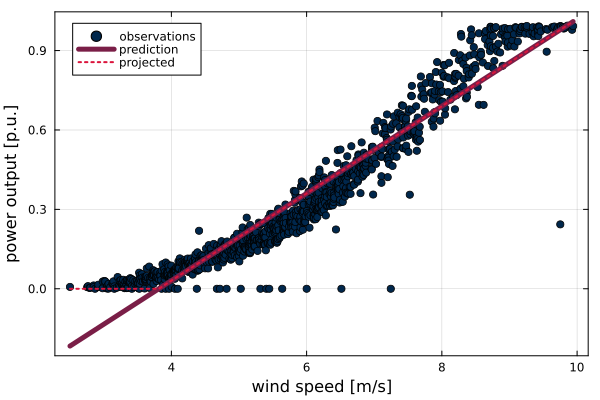

In [62]:
using Plots
using JSON
using Colors

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
myred = RGB(220/256, 20/256, 60/256)

# Load wind power records
dataset = JSON.parsefile("wind_power_data.json")
n = length(dataset["ActivePower"])

sort_index = sortperm(dataset["WindSpeed"])
t = dataset["ActivePower"][sort_index]
x = dataset["WindSpeed"][sort_index]

# Parameters for gradient descent
α = 0.01
iter_max = 25000

cost_function(w, b) = 1/(2*n) * sum((w*x[i] + b - t[i])^2 for i in 1:n)

w, b = 0, 0
cost = zeros(iter_max)

for i in 1:iter_max

    # Prediction
    ŷ = w .* x .+ b

    # Calculate gradients
    dw = (1/n) * sum((ŷ[j] - t[j]) * x[j] for j in 1:n)
    db = (1/n) * sum(ŷ[j] - t[j] for j in 1:n)

    # Gradient descent updates
    w = w - α * dw
    b = b - α * db

    # Store cost
    cost[i] = cost_function(w, b)

end

# Plot gradient descent dynamics
plot_gd = plot(
    cost,
    lw=5,
    c=purple,
    frame=:box,
    xlabel="iteration index",
    ylabel="cost function"
)

# Plot wind power curve
plot_wp = scatter(
    x,
    t,
    c=blue,
    frame=:box,
    xlabel="wind speed [m/s]",
    ylabel="power output [p.u.]",
    label="observations"
)

plot!(
    x,
    w .* x .+ b,
    lw=5,
    c=purple,
    label="prediction"
)

plot!(
    x,
    max.(w .* x .+ b, 0),
    lw=2,
    c=myred,
    linestyle=:dot,
    label="projected"
)


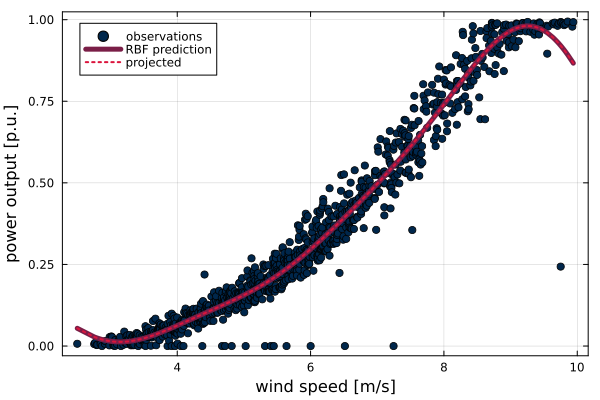

In [63]:
using Plots
using JSON
using Colors

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
myred = RGB(220/256, 20/256, 60/256)

# Load wind power records
dataset = JSON.parsefile("wind_power_data.json")
n = length(dataset["ActivePower"])

sort_index = sortperm(dataset["WindSpeed"])
t = dataset["ActivePower"][sort_index]
x = dataset["WindSpeed"][sort_index]

# ---------------------------------------------------------
# Radial Basis Function feature transformation
# ---------------------------------------------------------

# Number of RBF features
num_features = 10

# Choose RBF centers across the wind-speed range
centers = range(minimum(x), maximum(x), length=num_features)

# Width of the RBFs
σ = (maximum(x) - minimum(x)) / (num_features - 1)

# Create feature matrix
Φ = zeros(n, num_features)

for i in 1:n
    for j in 1:num_features
        Φ[i,j] = exp(-(x[i] - centers[j])^2 / (2 * σ^2))
    end
end

# ---------------------------------------------------------
# Gradient descent
# ---------------------------------------------------------

α = 0.01
iter_max = 25000

# One weight for each RBF feature
w = zeros(num_features)

# Bias
b = 0.0

cost = zeros(iter_max)

for i in 1:iter_max

    # Prediction using RBF features
    ŷ = Φ * w .+ b

    # Gradients
    dw = (1/n) .* (Φ' * (ŷ - t))
    db = (1/n) * sum(ŷ - t)

    # Gradient descent updates
    w = w - α .* dw
    b = b - α * db

    # Cost
    cost[i] = (1/(2*n)) * sum((ŷ - t).^2)

end

# ---------------------------------------------------------
# Plot gradient descent dynamics
# ---------------------------------------------------------

plot_gd = plot(
    cost,
    lw=5,
    c=purple,
    frame=:box,
    xlabel="iteration index",
    ylabel="cost function",
    label=""
)

# ---------------------------------------------------------
# Plot wind power curve
# ---------------------------------------------------------

prediction = Φ * w .+ b

plot_wp = scatter(
    x,
    t,
    c=blue,
    frame=:box,
    xlabel="wind speed [m/s]",
    ylabel="power output [p.u.]",
    label="observations"
)

plot!(
    x,
    prediction,
    lw=5,
    c=purple,
    label="RBF prediction"
)

plot!(
    x,
    max.(prediction, 0),
    lw=2,
    c=myred,
    linestyle=:dot,
    label="projected"
)

Best validation RMSE: 0.061665
Best iteration: 24999
Final training RMSE: 0.060617


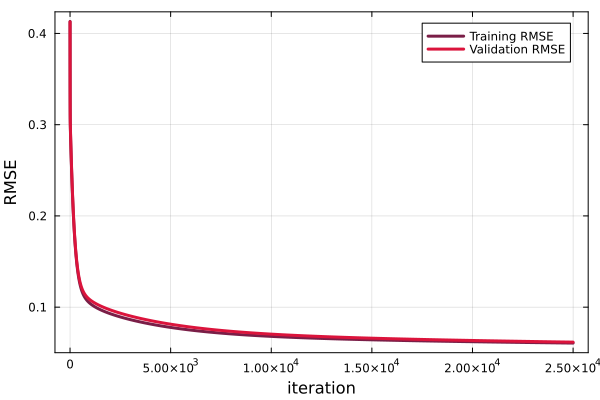

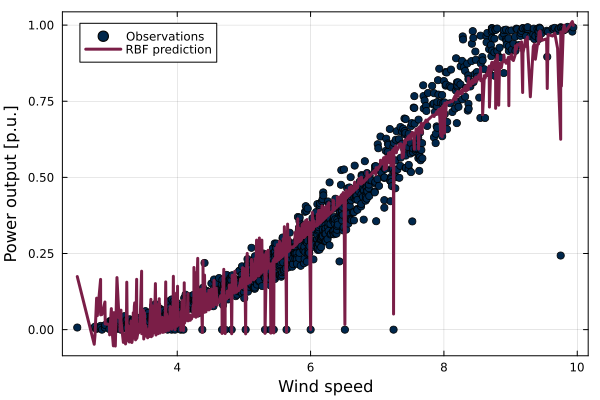

In [65]:

using Plots
using JSON
using Colors
using Statistics
using Random

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
myred = RGB(220/256, 20/256, 60/256)

# ---------------------------------------------------------
# Load wind power records
# ---------------------------------------------------------

dataset = JSON.parsefile("wind_power_data.json")

n = length(dataset["ActivePower"])

# Target
t = Float64.(dataset["ActivePower"])

# Raw features
X_raw = hcat(
    Float64.(dataset["WindSpeed"]),
    Float64.(dataset["WindDirection"]),
    Float64.(dataset["Blade1PitchAngle"])
)

# ---------------------------------------------------------
# Split data into training and validation sets
# ---------------------------------------------------------

Random.seed!(42)

indices = randperm(n)
n_train = floor(Int, 0.8 * n)

train_idx = indices[1:n_train]
val_idx = indices[n_train+1:end]

t_train = t[train_idx]
t_val = t[val_idx]

# ---------------------------------------------------------
# Standardize features using training data only
# ---------------------------------------------------------

feature_mean = mean(X_raw[train_idx, :], dims=1)
feature_std = std(X_raw[train_idx, :], dims=1)

# Avoid division by zero for constant features
feature_std[feature_std .== 0] .= 1.0

X = (X_raw .- feature_mean) ./ feature_std

X_train = X[train_idx, :]
X_val = X[val_idx, :]

# ---------------------------------------------------------
# Radial Basis Function transformation
# ---------------------------------------------------------

# Fewer centers reduce model complexity
num_features = 30

# Select centers from training data only
center_order = sortperm(X_train[:, 1])
center_positions = round.(Int,
    range(1, n_train, length=num_features))

center_indices = center_order[center_positions]
centers = X_train[center_indices, :]

# Wider Gaussian functions produce a smoother model
σ = 2.5

function rbf_features(X, centers, σ)
    n_samples = size(X, 1)
    n_centers = size(centers, 1)
    n_inputs = size(X, 2)

    Φ = zeros(n_samples, n_centers)

    for i in 1:n_samples
        for j in 1:n_centers
            distance_squared = sum(
                (X[i, k] - centers[j, k])^2
                for k in 1:n_inputs
            )

            Φ[i, j] = exp(
                -distance_squared / (2 * σ^2)
            )
        end
    end

    return Φ
end

Φ_train = rbf_features(X_train, centers, σ)
Φ_val = rbf_features(X_val, centers, σ)

# ---------------------------------------------------------
# Gradient descent parameters
# ---------------------------------------------------------

α = 0.01
λ = 0.1
iter_max = 25000

# Early stopping parameters
patience = 1000
min_improvement = 1e-6

w = zeros(num_features)
b = 0.0

best_w = copy(w)
best_b = b
best_val_rmse = Inf
epochs_without_improvement = 0
best_iteration = 0

train_cost = Float64[]
train_rmse = Float64[]
val_rmse = Float64[]

# ---------------------------------------------------------
# Gradient descent with regularization and early stopping
# ---------------------------------------------------------

for i in 1:iter_max

    # Training predictions and errors
    ŷ_train = Φ_train * w .+ b
    error = ŷ_train - t_train

    # Gradients, including L2 regularization
    dw = (Φ_train' * error) / n_train .+
         (λ / n_train) .* w

    db = sum(error) / n_train

    # Update parameters
    w -= α .* dw
    b -= α * db

    # Evaluate updated model
    ŷ_train = Φ_train * w .+ b
    ŷ_val = Φ_val * w .+ b

    error_train = ŷ_train - t_train

    # Regularized training objective
    current_cost =
        sum(error_train.^2) / (2 * n_train) +
        λ * sum(w.^2) / (2 * n_train)

    current_train_rmse = sqrt(
        mean(error_train.^2)
    )

    current_val_rmse = sqrt(
        mean((ŷ_val - t_val).^2)
    )

    push!(train_cost, current_cost)
    push!(train_rmse, current_train_rmse)
    push!(val_rmse, current_val_rmse)

    # Save the model whenever validation improves
    if current_val_rmse < best_val_rmse - min_improvement
        best_val_rmse = current_val_rmse
        best_w = copy(w)
        best_b = b
        best_iteration = i
        epochs_without_improvement = 0
    else
        epochs_without_improvement += 1
    end

    # Stop when validation performance stops improving
    if epochs_without_improvement >= patience
        println("Early stopping at iteration $i")
        break
    end
end

# Restore the best validation model
w = best_w
b = best_b

println("Best validation RMSE: ", round(best_val_rmse, digits=6))
println("Best iteration: ", best_iteration)
println("Final training RMSE: ", round(train_rmse[end], digits=6))

# ---------------------------------------------------------
# Plot training dynamics
# ---------------------------------------------------------

plot_gd = plot(
    train_rmse,
    lw=3,
    c=purple,
    label="Training RMSE",
    frame=:box,
    xlabel="iteration",
    ylabel="RMSE"
)

plot!(
    plot_gd,
    val_rmse,
    lw=3,
    c=myred,
    label="Validation RMSE"
)

display(plot_gd)

# ---------------------------------------------------------
# Predictions for all observations
# ---------------------------------------------------------

Φ_all = rbf_features(X, centers, σ)
prediction = Φ_all * w .+ b

# Sort by wind speed for a readable plot
sort_index = sortperm(dataset["WindSpeed"])

wind_speed_plot = dataset["WindSpeed"][sort_index]
target_plot = t[sort_index]
prediction_plot = prediction[sort_index]

# ---------------------------------------------------------
# Plot prediction against wind speed
# ---------------------------------------------------------

plot_wp = scatter(
    wind_speed_plot,
    target_plot,
    c=blue,
    frame=:box,
    xlabel="Wind speed",
    ylabel="Power output [p.u.]",
    label="Observations"
)

plot!(
    plot_wp,
    wind_speed_plot,
    prediction_plot,
    lw=3,
    c=purple,
    label="RBF prediction"
)

display(plot_wp)

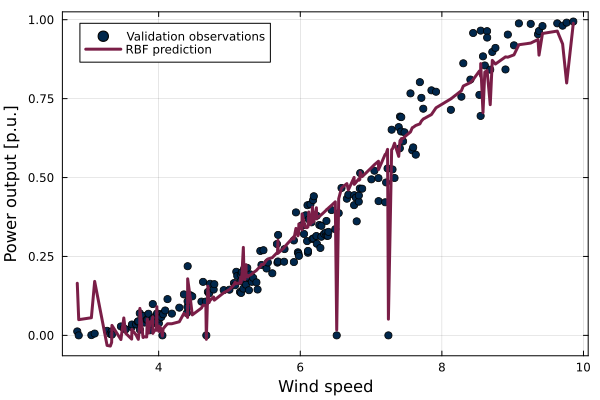

In [66]:

# ---------------------------------------------------------
# Validation-only prediction plot
# ---------------------------------------------------------

# Sort validation observations by wind speed for readability
val_sort_index = sortperm(X_raw[val_idx, 1])

wind_speed_val = X_raw[val_idx, 1][val_sort_index]
target_val_plot = t_val[val_sort_index]

# Predictions from the best model, using validation data only
prediction_val = (Φ_val * w .+ b)[val_sort_index]

plot_val = scatter(
    wind_speed_val,
    target_val_plot,
    c=blue,
    frame=:box,
    xlabel="Wind speed",
    ylabel="Power output [p.u.]",
    label="Validation observations"
)

plot!(
    plot_val,
    wind_speed_val,
    prediction_val,
    lw=3,
    c=purple,
    label="RBF prediction"
)

display(plot_val)

In [67]:
using CSV
using DataFrames

df = CSV.read("Location1.csv", DataFrame)

Row,Time,temperature_2m,relativehumidity_2m,dewpoint_2m,windspeed_10m,windspeed_100m,winddirection_10m,winddirection_100m,windgusts_10m,Power
,Timestam…,Float64,Int64,Float64,Float64,Float64,Int64,Int64,Float64,Float64
1,2017-01-02T00:00:00,28.5,85,24.5,1.44,1.26,146,162,1.4,0.1635
2,2017-01-02T01:00:00,28.4,86,24.7,2.06,3.99,151,158,4.4,0.1424
3,2017-01-02T02:00:00,26.8,91,24.5,1.3,2.78,148,150,3.2,0.1214
4,2017-01-02T03:00:00,27.4,88,24.3,1.3,2.69,58,105,1.6,0.1003
5,2017-01-02T04:00:00,27.3,88,24.1,2.47,4.43,58,84,4.0,0.0793
6,2017-01-02T05:00:00,27.6,90,25.2,2.73,5.59,66,80,4.5,0.0778
7,2017-01-02T06:00:00,26.7,92,24.9,2.1,5.82,65,78,4.7,0.0959
8,2017-01-02T07:00:00,28.4,91,26.1,3.1,6.24,69,78,4.8,0.1141
9,2017-01-02T08:00:00,30.2,88,27.0,3.54,6.89,74,81,5.8,0.1322


In [68]:
temperature_2m = df.temperature_2m
relativehumidity_2m = df.relativehumidity_2m
dewpoint_2m = df.dewpoint_2m	
windspeed_10m = df.windspeed_10m
windspeed_100m = df.windspeed_100m
winddirection_10m = df.winddirection_10m	
winddirection_100m = df.winddirection_100m
windgusts_10m = df.windgusts_10m
Power = df.Power

43800-element Vector{Float64}:
 0.1635
 0.1424
 0.1214
 0.1003
 0.0793
 0.0778
 0.0959
 0.1141
 0.1322
 0.1503
 0.1684
 0.1866
 0.2066
 ⋮
 0.1585
 0.155
 0.1515
 0.1479
 0.1444
 0.1408
 0.1526
 0.1796
 0.2066
 0.2336
 0.2606
 0.2877

RMSE: 0.225962457303042


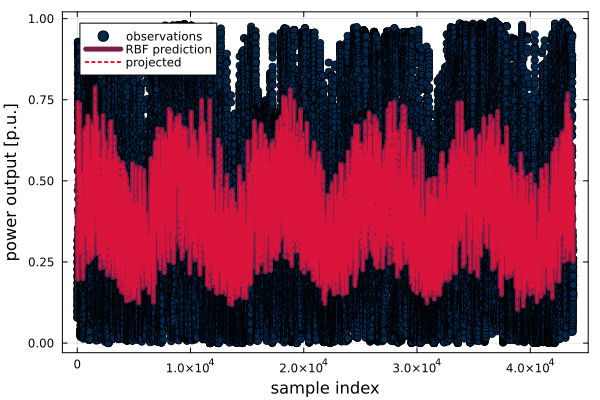

In [45]:
using Plots
using JSON
using Colors
using DataFrames
using CSV
using Statistics

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
myred = RGB(220/256, 20/256, 60/256)

# ---------------------------------------------------------
# Load dataset
# ---------------------------------------------------------

df = CSV.read("Location1.csv", DataFrame)

# Input variables
temperature_2m       = df.temperature_2m
relativehumidity_2m  = df.relativehumidity_2m
dewpoint_2m          = df.dewpoint_2m
windspeed_10m        = df.windspeed_10m
windspeed_100m       = df.windspeed_100m
winddirection_10m    = df.winddirection_10m
winddirection_100m   = df.winddirection_100m
windgusts_10m        = df.windgusts_10m

# Target variable
Power = df.Power

n = length(Power)

# ---------------------------------------------------------
# Create input matrix
# ---------------------------------------------------------

X = hcat(
    temperature_2m,
    relativehumidity_2m,
    dewpoint_2m,
    windspeed_10m,
    windspeed_100m,
    winddirection_10m,
    winddirection_100m,
    windgusts_10m
)

# ---------------------------------------------------------
# Normalize input variables
# ---------------------------------------------------------

X_min = minimum(X, dims=1)
X_max = maximum(X, dims=1)

X_norm = (X .- X_min) ./ (X_max .- X_min)

# ---------------------------------------------------------
# Radial Basis Function feature transformation
# ---------------------------------------------------------

num_features = 30

# Create one center for each RBF feature
center_indices = range(1, n, length=num_features)

centers = X_norm[round.(Int, center_indices), :]

# Width of RBF
σ = 2.0

Φ = zeros(n, num_features)

for i in 1:n
    for j in 1:num_features

        distance_squared = sum(
            (X_norm[i, :] .- centers[j, :]).^2
        )

        Φ[i,j] = exp(
            -distance_squared / (2 * σ^2)
        )
    end
end

# ---------------------------------------------------------
# Gradient descent parameters
# ---------------------------------------------------------

α = 0.01
λ = 0.001
iter_max = 25000

w = zeros(num_features)
b = 0.0

cost = zeros(iter_max)

# ---------------------------------------------------------
# Gradient descent
# ---------------------------------------------------------

for i in 1:iter_max

    # Prediction
    ŷ = Φ * w .+ b

    # Prediction error
    error = ŷ - Power

    # Gradients
    dw = (1/n) .* (Φ' * error) + (λ/n) .* w
    db = (1/n) * sum(error)

    # Gradient descent updates
    w = w - α .* dw
    b = b - α * db

    # Regularized cost
    cost[i] =
        (1/(2*n)) * sum(error.^2) +
        (λ/(2*n)) * sum(w.^2)
end

# ---------------------------------------------------------
# Plot gradient descent dynamics
# ---------------------------------------------------------

plot_gd = plot(
    cost,
    lw=5,
    c=purple,
    frame=:box,
    xlabel="iteration index",
    ylabel="regularized cost",
    label=""
)

# ---------------------------------------------------------
# Plot predicted vs actual power
# ---------------------------------------------------------

prediction = Φ * w .+ b

# Calculate RMSE
rmse = sqrt(mean((prediction .- Power).^2))

println("RMSE: ", rmse)

plot_wp = scatter(
    1:n,
    Power,
    c=blue,
    frame=:box,
    xlabel="sample index",
    ylabel="power output [p.u.]",
    label="observations"
)

plot!(
    1:n,
    prediction,
    lw=5,
    c=purple,
    label="RBF prediction"
)

plot!(
    1:n,
    max.(prediction, 0),
    lw=2,
    c=myred,
    linestyle=:dot,
    label="projected"
)

Best validation RMSE: 0.174697
Best iteration: 24984
Final training RMSE: 0.170929


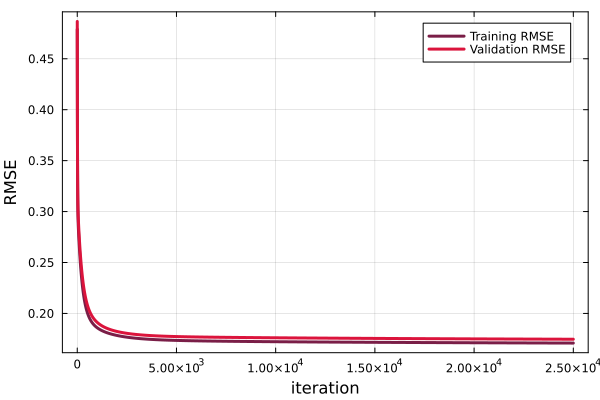

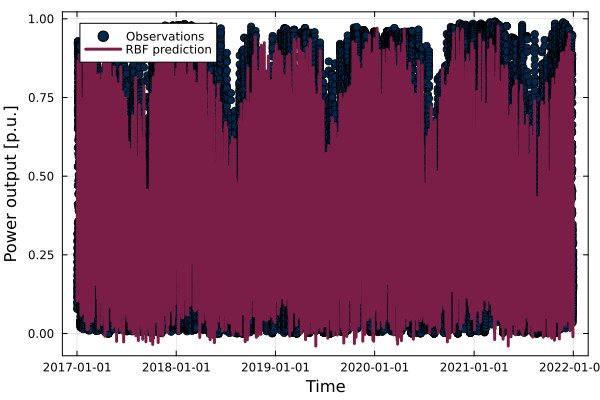

In [72]:
using Dates
using Plots
using JSON
using Colors
using Statistics
using Random
using CSV
using DataFrames

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
myred = RGB(220/256, 20/256, 60/256)

# ---------------------------------------------------------
# Load wind power records
# ---------------------------------------------------------

dataset = CSV.read("Location1.csv", DataFrame)

# Convert timestamp column to DateTime
dataset.Time = DateTime.(dataset.Time)

# Sort chronologically
sort!(dataset, order(:Time))

n = nrow(dataset)

# Target
t = Float64.(dataset.Power)

# Extract hour of day
hour = Dates.hour.(dataset.Time)

# Cyclical encoding of hour (23:00 is close to 00:00)
hour_sin = sin.(2π .* hour ./ 24)
hour_cos = cos.(2π .* hour ./ 24)


# Raw features
X_raw = hcat(
    Float64.(dataset.temperature_2m),
    Float64.(dataset.relativehumidity_2m),
    Float64.(dataset.dewpoint_2m),
    Float64.(dataset.windspeed_10m),
    Float64.(dataset.windspeed_100m),
    Float64.(dataset.winddirection_10m),
    Float64.(dataset.winddirection_100m),
    Float64.(dataset.windgusts_10m),
    hour_sin,
    hour_cos
)


# ---------------------------------------------------------
# Split data into chronological training and validation sets
# ---------------------------------------------------------

n = length(t)
n_train = floor(Int, 0.8 * n)

train_idx = 1:n_train
val_idx = (n_train + 1):n

t_train = t[train_idx]
t_val = t[val_idx]

# ---------------------------------------------------------
# Standardize features using training data only
# ---------------------------------------------------------

feature_mean = mean(X_raw[train_idx, :], dims=1)
feature_std = std(X_raw[train_idx, :], dims=1)

# Avoid division by zero for constant features
feature_std[feature_std .== 0] .= 1.0

# Standardize using training statistics
X = (X_raw .- feature_mean) ./ feature_std

X_train = X[train_idx, :]
X_val = X[val_idx, :]

# ---------------------------------------------------------
# Radial Basis Function transformation
# ---------------------------------------------------------

# Number of RBF centers
num_features = 30

# Select centers randomly from training data only
center_indices = randperm(n_train)[1:num_features]
centers = X_train[center_indices, :]

# RBF width
σ = 3

function rbf_features(X, centers, σ)
    n_samples = size(X, 1)
    n_centers = size(centers, 1)
    n_inputs = size(X, 2)

    Φ = zeros(n_samples, n_centers)

    for i in 1:n_samples
        for j in 1:n_centers
            distance_squared = sum(
                (X[i, k] - centers[j, k])^2
                for k in 1:n_inputs
            )

            Φ[i, j] = exp(
                -distance_squared / (2 * σ^2)
            )
        end
    end

    return Φ
end

Φ_train = rbf_features(X_train, centers, σ)
Φ_val = rbf_features(X_val, centers, σ)

# ---------------------------------------------------------
# Gradient descent parameters
# ---------------------------------------------------------

α = 0.01
λ = 0.1
iter_max = 25000

# Early stopping parameters
patience = 1000
min_improvement = 1e-6

w = zeros(num_features)
b = 0.0

best_w = copy(w)
best_b = b
best_val_rmse = Inf
epochs_without_improvement = 0
best_iteration = 0

train_cost = Float64[]
train_rmse = Float64[]
val_rmse = Float64[]

# ---------------------------------------------------------
# Gradient descent with regularization and early stopping
# ---------------------------------------------------------

for i in 1:iter_max

    # Training predictions and errors
    ŷ_train = Φ_train * w .+ b
    error = ŷ_train - t_train

    # Gradients, including L2 regularization
    dw = (Φ_train' * error) / n_train .+
         (λ / n_train) .* w

    db = sum(error) / n_train

    # Update parameters
    w -= α .* dw
    b -= α * db

    # Evaluate updated model
    ŷ_train = Φ_train * w .+ b
    ŷ_val = Φ_val * w .+ b

    error_train = ŷ_train - t_train

    # Regularized training objective
    current_cost =
        sum(error_train.^2) / (2 * n_train) +
        λ * sum(w.^2) / (2 * n_train)

    current_train_rmse = sqrt(
        mean(error_train.^2)
    )

    current_val_rmse = sqrt(
        mean((ŷ_val - t_val).^2)
    )

    push!(train_cost, current_cost)
    push!(train_rmse, current_train_rmse)
    push!(val_rmse, current_val_rmse)

    # Save the model whenever validation improves
    if current_val_rmse < best_val_rmse - min_improvement
        best_val_rmse = current_val_rmse
        best_w = copy(w)
        best_b = b
        best_iteration = i
        epochs_without_improvement = 0
    else
        epochs_without_improvement += 1
    end

    # Stop when validation performance stops improving
    if epochs_without_improvement >= patience
        println("Early stopping at iteration $i")
        break
    end
end

# Restore the best validation model
w = best_w
b = best_b

println("Best validation RMSE: ", round(best_val_rmse, digits=6))
println("Best iteration: ", best_iteration)
println("Final training RMSE: ", round(train_rmse[end], digits=6))

# ---------------------------------------------------------
# Plot training dynamics
# ---------------------------------------------------------

plot_gd = plot(
    train_rmse,
    lw=3,
    c=purple,
    label="Training RMSE",
    frame=:box,
    xlabel="iteration",
    ylabel="RMSE"
)

plot!(
    plot_gd,
    val_rmse,
    lw=3,
    c=myred,
    label="Validation RMSE"
)

display(plot_gd)

# ---------------------------------------------------------
# Predictions for all observations
# ---------------------------------------------------------

Φ_all = rbf_features(X, centers, σ)
prediction = Φ_all * w .+ b

# Sort by wind speed for a readable plot
sort_index = sortperm(dataset.windspeed_100m)

wind_speed_plot = dataset.windspeed_100m[sort_index]
target_plot = t[sort_index]
prediction_plot = prediction[sort_index]

# ---------------------------------------------------------
# Plot prediction against time
# ---------------------------------------------------------

time_plot = dataset.Time

plot_wp = scatter(
    time_plot,
    t,
    c=blue,
    frame=:box,
    xlabel="Time",
    ylabel="Power output [p.u.]",
    label="Observations"
)

plot!(
    plot_wp,
    time_plot,
    prediction,
    lw=3,
    c=purple,
    label="RBF prediction"
)

display(plot_wp)

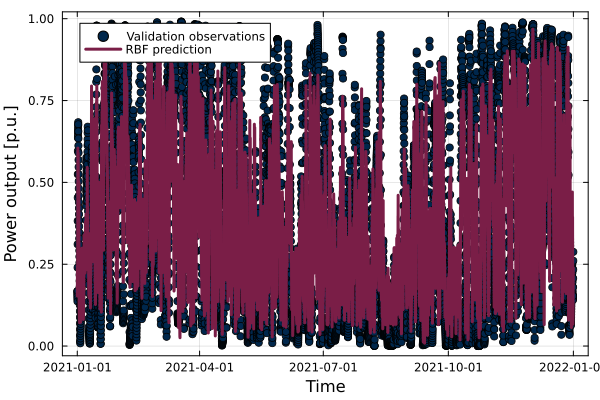

In [71]:
# ---------------------------------------------------------
# Validation-only prediction plot by time
# ---------------------------------------------------------

# Validation timestamps
time_val = dataset.Time[val_idx]

# Predictions from the best model, using validation data only
prediction_val = Φ_val * w .+ b

plot_val = scatter(
    time_val,
    t_val,
    c=blue,
    frame=:box,
    xlabel="Time",
    ylabel="Power output [p.u.]",
    label="Validation observations"
)

plot!(
    plot_val,
    time_val,
    prediction_val,
    lw=3,
    c=purple,
    label="RBF prediction"
)

display(plot_val)